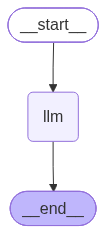

In [22]:


from IPython.core.display import Image
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState

model = init_chat_model(
    "deepseek-flash",
    extra_body={"thinking": {"type": "disabled"}}
)


# State
# 方式一：继承TypedDict，自已定义messages字段
# class LLMState(TypedDict):
#     messages: Annotated[list[BaseMessage], add]

# 方式二：直接继承MessagesState
# class LLMState(MessagesState):
#     pass

# 方式三：不自定义State，直接使用MessagesState


# Node
def llm_node(state: MessagesState):
    ai_message = model.invoke(state.get("messages"))
    return {"messages": [ai_message]}


# Edge
builder = StateGraph(MessagesState)

builder.add_node("llm", llm_node)

builder.add_edge(START, "llm")
builder.add_edge("llm", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [23]:
res = graph.invoke({"messages": [HumanMessage("你是谁")]})
print(f"===================len:{len(res["messages"])}===================")
print(f"res = {res}")

===================len:2===================
res = {'messages': [HumanMessage(content='你是谁', additional_kwargs={}, response_metadata={}, id='a930c16c-533b-4a80-a109-cbcd67cfd6ae'), AIMessage(content='你好！我是DeepSeek，由深度求索公司创造的AI助手。😊\n\n我可以帮你解答问题、进行对话、提供信息等。我的一些特点包括：\n\n- **免费使用**：目前完全免费，没有任何收费计划\n- **支持多模态**：可以接收图片输入，识别和分析图片中的可见信息\n- **文件处理**：支持上传图像、txt、pdf、ppt、word、excel等文件，并从中读取文字信息\n- **超长上下文**：支持1M上下文，可以一次性处理像《三体》三部曲那样体量的书籍\n- **联网搜索**：支持联网搜索功能（需要手动开启）\n- **语音输入**：App端支持语音输入\n\n我的知识截止日期是2026年2月。有什么我可以帮你的吗？无论是学习、工作还是生活上的问题，都可以问我哦！✨', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 183, 'prompt_tokens': 5, 'total_tokens': 188, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 